In [1]:

# ==========================================
# AdaServe - Step 1: Environment Setup
# ==========================================

import os
import sys
import torch
import random
import numpy as np

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Check Python and PyTorch
print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)

# Check GPU availability
if torch.cuda.is_available():
    print("\nGPU Available:", torch.cuda.get_device_name(0))
    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
          "GB")
else:
    print("\nNo GPU available. CPU mode enabled.")

# Create project folders
project_path = "/content/AdaServe"

folders = [
    "datasets",
    "models",
    "src",
    "evaluation",
    "results",
    "results/graphs"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("\nProject folders created successfully!")
print("Project location:", project_path)


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.14.1+cu130

GPU Available: Tesla T4
GPU Memory: 15.64 GB

Project folders created successfully!
Project location: /content/AdaServe


In [2]:

# AdaServe - Step 2: Install Dependencies

%pip install -q "transformers>=4.48,<5" accelerate datasets pandas matplotlib sentencepiece

print("Required libraries installed successfully!")


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
Required libraries installed successfully!


In [3]:

import torch
import transformers
import datasets
import pandas
import matplotlib

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Pandas:", pandas.__version__)
print("Matplotlib:", matplotlib.__version__)

print("\nAll required libraries imported successfully!")


PyTorch: 2.14.1+cu130
Transformers: 4.57.6
Datasets: 4.8.5
Pandas: 2.2.3
Matplotlib: 3.10.0

All required libraries imported successfully!


In [4]:

# ==========================================
# AdaServe - Step 3: Load Draft and Target Models
# ==========================================

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

DRAFT_ID = "Qwen/Qwen2.5-0.5B-Instruct"
TARGET_ID = "Qwen/Qwen2.5-1.5B-Instruct"

# Load tokenizer
print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(TARGET_ID)

# Load draft model
print("\nLoading draft model...")
draft_model = AutoModelForCausalLM.from_pretrained(
    DRAFT_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)

# Load target model
print("\nLoading target model...")
target_model = AutoModelForCausalLM.from_pretrained(
    TARGET_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)

# Evaluation mode
draft_model.eval()
target_model.eval()

print("\nBoth models loaded successfully!")

print("Draft parameters:",
      sum(p.numel() for p in draft_model.parameters()))

print("Target parameters:",
      sum(p.numel() for p in target_model.parameters()))

print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1e9, 2), "GB")


Loading tokenizer...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (6 outputs left out)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


Both models loaded successfully!
Draft parameters: 494032768
Target parameters: 1543714304
GPU memory allocated: 4.08 GB


In [5]:

# ==========================================
# AdaServe - Step 4: Test Model Generation
# ==========================================

prompt = "Explain artificial intelligence in simple words."

messages = [
    {"role": "user", "content": prompt}
]

input_text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(
    input_text,
    return_tensors="pt"
).to("cuda")

# Draft model generation
with torch.no_grad():
    draft_output = draft_model.generate(
        **inputs,
        max_new_tokens=50,
        do_sample=False
    )

# Target model generation
with torch.no_grad():
    target_output = target_model.generate(
        **inputs,
        max_new_tokens=50,
        do_sample=False
    )

print("DRAFT MODEL RESPONSE:")
print(tokenizer.decode(
    draft_output[0][inputs.input_ids.shape[1]:],
    skip_special_tokens=True
))

print("\nTARGET MODEL RESPONSE:")
print(tokenizer.decode(
    target_output[0][inputs.input_ids.shape[1]:],
    skip_special_tokens=True
))


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


DRAFT MODEL RESPONSE:
Artificial Intelligence (AI) is a field of computer science that focuses on creating intelligent machines that can perform tasks that typically require human intelligence, such as learning, problem-solving, decision-making, and understanding language. AI systems use algorithms and statistical models to

TARGET MODEL RESPONSE:
Artificial Intelligence (AI) is the simulation of human intelligence processes by machines, especially computer systems. These processes include learning, reasoning, and self-correction. AI allows computers to perform tasks that typically require human intelligence, such as visual perception, speech


In [12]:

# ==========================================
# AdaServe - Step 5.5
# Greedy Speculative Decoding (Corrected)
# ==========================================

import torch
import time

def speculative_decoding_v3(
    prompt,
    draft_model,
    target_model,
    tokenizer,
    speculation_depth=4,
    max_new_tokens=80
):
    messages = [{"role": "user", "content": prompt}]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    input_ids = tokenizer(
        text, return_tensors="pt"
    ).input_ids.to("cuda")

    generated = []
    proposed = 0
    accepted = 0
    rounds = 0

    eos = target_model.generation_config.eos_token_id
    if eos is None:
        eos = tokenizer.eos_token_id
    eos_ids = set(eos if isinstance(eos, list) else [eos])

    start = time.time()

    while len(generated) < max_new_tokens:
        rounds += 1
        prefix = input_ids
        draft_sequence = prefix
        candidates = []

        # 1. Draft candidate generation
        with torch.inference_mode():
            for _ in range(min(
                speculation_depth,
                max_new_tokens - len(generated)
            )):
                logits = draft_model(
                    input_ids=draft_sequence
                ).logits[:, -1, :]

                token = logits.argmax(dim=-1).item()
                candidates.append(token)

                draft_sequence = torch.cat([
                    draft_sequence,
                    torch.tensor([[token]], device="cuda")
                ], dim=1)

                if token in eos_ids:
                    break

            proposed += len(candidates)

            # 2. Target verifies candidate sequence
            candidate_tensor = torch.tensor(
                [candidates], device="cuda"
            )

            verify_ids = torch.cat(
                [prefix, candidate_tensor], dim=1
            )

            target_logits = target_model(
                input_ids=verify_ids
            ).logits

            prefix_len = prefix.shape[1]
            new_tokens = []
            all_accepted = True

            # 3. Compare each candidate with target prediction
            for j, candidate in enumerate(candidates):

                target_token = target_logits[
                    0, prefix_len - 1 + j, :
                ].argmax().item()

                if candidate == target_token:
                    new_tokens.append(candidate)
                    accepted += 1

                    if candidate in eos_ids:
                        break

                else:
                    all_accepted = False
                    new_tokens.append(target_token)
                    break

            # 4. Add bonus token only if ALL candidates match
            if (
                all_accepted
                and len(new_tokens) == len(candidates)
                and new_tokens
                and new_tokens[-1] not in eos_ids
                and len(generated) + len(new_tokens) < max_new_tokens
            ):
                bonus = target_logits[
                    0, prefix_len + len(candidates) - 1, :
                ].argmax().item()

                new_tokens.append(bonus)

            # Limit output to requested length
            remaining = max_new_tokens - len(generated)
            new_tokens = new_tokens[:remaining]

            if not new_tokens:
                break

            generated.extend(new_tokens)

            # 5. Update prefix
            input_ids = torch.cat([
                prefix,
                torch.tensor([new_tokens], device="cuda")
            ], dim=1)

            # Stop on EOS
            if new_tokens[-1] in eos_ids:
                break

    return {
        "token_ids": generated,
        "response": tokenizer.decode(
            generated, skip_special_tokens=True
        ),
        "accepted_tokens": accepted,
        "proposed_tokens": proposed,
        "acceptance_rate": accepted / proposed if proposed else 0,
        "rounds": rounds,
        "latency": time.time() - start
    }


print("V3 speculative decoding function defined!")


V3 speculative decoding function defined!


In [13]:

prompt = "Explain machine learning in simple words."

messages = [{"role": "user", "content": prompt}]
text = tokenizer.apply_chat_template(
    messages, tokenize=False, add_generation_prompt=True
)

inputs = tokenizer(text, return_tensors="pt").to("cuda")

# Target-only greedy baseline
with torch.inference_mode():
    baseline = target_model.generate(
        **inputs,
        max_new_tokens=80,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

baseline_tokens = baseline[
    0, inputs.input_ids.shape[1]:
].tolist()

# Speculative decoding V3
result = speculative_decoding_v3(
    prompt,
    draft_model,
    target_model,
    tokenizer,
    speculation_depth=4,
    max_new_tokens=80
)

print("VALIDATION RESULTS")
print("-" * 40)
print("Target tokens:", len(baseline_tokens))
print("Speculative tokens:", len(result["token_ids"]))
print("Exact output match:",
      baseline_tokens == result["token_ids"])
print("Acceptance rate:",
      round(result["acceptance_rate"] * 100, 2), "%")
print("Rounds:", result["rounds"])
print("Latency:", round(result["latency"], 3), "seconds")


VALIDATION RESULTS
----------------------------------------
Target tokens: 80
Speculative tokens: 71
Exact output match: False
Acceptance rate: 85.94 %
Rounds: 16
Latency: 2.8 seconds


In [14]:

# ==========================================
# Debug speculative decoding mismatch
# ==========================================

baseline_list = baseline_tokens
speculative_list = result["token_ids"]

print("Baseline length:", len(baseline_list))
print("Speculative length:", len(speculative_list))

# Find first mismatch
limit = min(len(baseline_list), len(speculative_list))

first_mismatch = None

for i in range(limit):
    if baseline_list[i] != speculative_list[i]:
        first_mismatch = i
        break

if first_mismatch is None:
    print("\nNo mismatch in common positions.")

    if len(baseline_list) != len(speculative_list):
        print("Mismatch: output lengths differ.")
else:
    print("\nFirst mismatch position:", first_mismatch)

    print("Target token ID:", baseline_list[first_mismatch])
    print("Speculative token ID:", speculative_list[first_mismatch])

    print("Target token:",
          tokenizer.decode([baseline_list[first_mismatch]]))

    print("Speculative token:",
          tokenizer.decode([speculative_list[first_mismatch]]))

    print("\nTarget context:")
    print(tokenizer.decode(
        baseline_list[max(0, first_mismatch-5):first_mismatch+5]
    ))

    print("\nSpeculative context:")
    print(tokenizer.decode(
        speculative_list[max(0, first_mismatch-5):first_mismatch+5]
    ))


Baseline length: 80
Speculative length: 71

First mismatch position: 39
Target token ID: 12624
Speculative token ID: 429
Target token:  patterns
Speculative token:  that

Target context:
 predictions or decisions based on patterns found within the data

Speculative context:
 predictions or decisions based on that data. The goal


In [15]:

# ==========================================
# AdaServe - Step 5.8: Prediction Diagnosis
# ==========================================

position = 39

# Reconstruct the exact target-model context
context_tokens = torch.tensor(
    [[
        *inputs.input_ids[0].tolist(),
        *baseline_tokens[:position]
    ]],
    device="cuda"
)

with torch.inference_mode():
    direct_logits = target_model(
        input_ids=context_tokens
    ).logits[0, -1, :]

direct_prediction = direct_logits.argmax().item()
expected_prediction = baseline_tokens[position]

print("Expected target token:",
      expected_prediction,
      tokenizer.decode([expected_prediction]))

print("Direct target prediction:",
      direct_prediction,
      tokenizer.decode([direct_prediction]))

print("Predictions agree:",
      direct_prediction == expected_prediction)

# Inspect the top five predictions
top_values, top_ids = torch.topk(direct_logits, 5)

print("\nTop 5 target predictions:")
for token_id, score in zip(top_ids.tolist(), top_values.tolist()):
    print(token_id, tokenizer.decode([token_id]), score)


Expected target token: 12624  patterns
Direct target prediction: 429  that
Predictions agree: False

Top 5 target predictions:
429  that 31.03125
12624  patterns 28.96875
279  the 28.015625
1846  those 26.15625
419  this 24.59375


In [16]:

# ==========================================
# Step 5.9: Target Model Consistency Test
# ==========================================

# Same context ending immediately before token 39
context = torch.tensor(
    [[
        *inputs.input_ids[0].tolist(),
        *baseline_tokens[:39]
    ]],
    device="cuda"
)

# Method 1: Direct forward pass
with torch.inference_mode():
    logits = target_model(input_ids=context).logits[:, -1, :]

direct_token = logits.argmax(dim=-1).item()

# Method 2: Generate one token from the same context
with torch.inference_mode():
    generated_one = target_model.generate(
        input_ids=context,
        max_new_tokens=1,
        do_sample=False,
        use_cache=True,
        pad_token_id=tokenizer.eos_token_id
    )

generate_token = generated_one[0, context.shape[1]].item()

# Method 3: Generate with cache disabled
with torch.inference_mode():
    generated_no_cache = target_model.generate(
        input_ids=context,
        max_new_tokens=1,
        do_sample=False,
        use_cache=False,
        pad_token_id=tokenizer.eos_token_id
    )

no_cache_token = generated_no_cache[0, context.shape[1]].item()

expected_token = baseline_tokens[39]

print("Expected baseline:", expected_token,
      tokenizer.decode([expected_token]))

print("Direct forward:", direct_token,
      tokenizer.decode([direct_token]))

print("Generate with cache:", generate_token,
      tokenizer.decode([generate_token]))

print("Generate without cache:", no_cache_token,
      tokenizer.decode([no_cache_token]))


The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


Expected baseline: 12624  patterns
Direct forward: 429  that
Generate with cache: 12624  patterns
Generate without cache: 12624  patterns


In [17]:

# ==========================================
# Step 5.10: Inspect Generation Configuration
# ==========================================

print("GENERATION CONFIGURATION")
print(target_model.generation_config)

# Build context and attention mask
context = torch.cat(
    [inputs.input_ids,
     torch.tensor([baseline_tokens[:39]], device="cuda")],
    dim=1
)

attention_mask = torch.ones_like(context)

# Raw forward prediction
with torch.inference_mode():
    raw_logits = target_model(
        input_ids=context,
        attention_mask=attention_mask
    ).logits[:, -1, :]

raw_token = raw_logits.argmax(dim=-1).item()

# Generation prediction and scores
with torch.inference_mode():
    output = target_model.generate(
        input_ids=context,
        attention_mask=attention_mask,
        max_new_tokens=1,
        do_sample=False,
        return_dict_in_generate=True,
        output_scores=True,
        pad_token_id=tokenizer.eos_token_id
    )

generate_token = output.sequences[0, context.shape[1]].item()
processed_token = output.scores[0].argmax(dim=-1).item()

print("\nRAW FORWARD TOKEN:",
      raw_token, tokenizer.decode([raw_token]))

print("GENERATE TOKEN:",
      generate_token, tokenizer.decode([generate_token]))

print("PROCESSED SCORE TOKEN:",
      processed_token, tokenizer.decode([processed_token]))

print("\nRaw and processed scores agree:",
      raw_token == processed_token)


GENERATION CONFIGURATION
GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "repetition_penalty": 1.1,
  "temperature": 0.7,
  "top_k": 20,
  "top_p": 0.8
}


RAW FORWARD TOKEN: 429  that
GENERATE TOKEN: 12624  patterns
PROCESSED SCORE TOKEN: 12624  patterns

Raw and processed scores agree: False


In [18]:

# ==========================================
# AdaServe - Step 5.11: Fair Greedy Validation
# ==========================================

prompt = "Explain machine learning in simple words."

messages = [{"role": "user", "content": prompt}]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(
    text,
    return_tensors="pt"
).to("cuda")

# Normal target generation with matching settings
with torch.inference_mode():
    baseline = target_model.generate(
        **inputs,
        max_new_tokens=80,
        do_sample=False,
        repetition_penalty=1.0,
        use_cache=False,
        pad_token_id=tokenizer.eos_token_id
    )

baseline_tokens = baseline[
    0, inputs.input_ids.shape[1]:
].tolist()

# Speculative decoding
result = speculative_decoding_v3(
    prompt=prompt,
    draft_model=draft_model,
    target_model=target_model,
    tokenizer=tokenizer,
    speculation_depth=4,
    max_new_tokens=80
)

print("FINAL GREEDY VALIDATION")
print("-" * 40)

print("Target tokens:", len(baseline_tokens))
print("Speculative tokens:", len(result["token_ids"]))

print("Exact output match:",
      baseline_tokens == result["token_ids"])

print("Acceptance rate:",
      round(result["acceptance_rate"] * 100, 2), "%")

print("Decoding rounds:", result["rounds"])
print("Latency:", round(result["latency"], 3), "seconds")


FINAL GREEDY VALIDATION
----------------------------------------
Target tokens: 71
Speculative tokens: 71
Exact output match: True
Acceptance rate: 85.94 %
Decoding rounds: 16
Latency: 2.379 seconds


In [19]:

# ==========================================
# AdaServe - Step 6: SLO Manager
# ==========================================

SLO_CONFIG = {
    "coding": {
        "type": "relative",
        "target": 1.2,
        "unit": "times baseline latency"
    },

    "chatbot": {
        "type": "absolute",
        "target": 50,
        "unit": "ms per token"
    },

    "summarization": {
        "type": "absolute",
        "target": 150,
        "unit": "ms per token"
    }
}

def get_slo(workload):
    workload = workload.lower()

    if workload not in SLO_CONFIG:
        raise ValueError("Unknown workload: " + workload)

    return SLO_CONFIG[workload]


# Test SLO manager
for workload in SLO_CONFIG:
    print(workload.upper(), ":", get_slo(workload))

print("\nSLO Manager created successfully!")


CODING : {'type': 'relative', 'target': 1.2, 'unit': 'times baseline latency'}
CHATBOT : {'type': 'absolute', 'target': 50, 'unit': 'ms per token'}
SUMMARIZATION : {'type': 'absolute', 'target': 150, 'unit': 'ms per token'}

SLO Manager created successfully!


In [20]:

# ==========================================
# AdaServe - Step 7: SLO Customized Selection
# ==========================================

def select_tokens(requests, verification_budget):

    # Sort requests by their SLO priority
    # Lower latency target = higher priority

    sorted_requests = sorted(
        requests,
        key=lambda x: x["priority"]
    )

    selected = []
    remaining_budget = verification_budget

    for request in sorted_requests:

        tokens_needed = request["tokens_needed"]

        if remaining_budget <= 0:
            break

        allocated = min(
            tokens_needed,
            remaining_budget
        )

        selected.append({
            "request": request["name"],
            "priority": request["priority"],
            "allocated_tokens": allocated
        })

        remaining_budget -= allocated

    return selected, remaining_budget


# Example requests
requests = [
    {
        "name": "Coding",
        "priority": 1,
        "tokens_needed": 4
    },
    {
        "name": "Chatbot",
        "priority": 2,
        "tokens_needed": 3
    },
    {
        "name": "Summarization",
        "priority": 3,
        "tokens_needed": 5
    }
]

# Total verification budget
verification_budget = 8

selected, remaining = select_tokens(
    requests,
    verification_budget
)

print("SLO-CUSTOMIZED TOKEN SELECTION")
print("-" * 40)

for item in selected:
    print(item)

print("\nRemaining verification budget:", remaining)


SLO-CUSTOMIZED TOKEN SELECTION
----------------------------------------
{'request': 'Coding', 'priority': 1, 'allocated_tokens': 4}
{'request': 'Chatbot', 'priority': 2, 'allocated_tokens': 3}
{'request': 'Summarization', 'priority': 3, 'allocated_tokens': 1}

Remaining verification budget: 0


In [21]:

# ==========================================
# AdaServe - Step 8: Throughput Optimization
# ==========================================

def optimize_throughput(requests, remaining_budget):

    allocations = []

    # Allocate remaining budget to requests
    # that can use additional verification tokens

    for request in requests:

        if remaining_budget <= 0:
            break

        additional_tokens = min(
            request["extra_capacity"],
            remaining_budget
        )

        if additional_tokens > 0:
            allocations.append({
                "request": request["name"],
                "additional_tokens": additional_tokens
            })

            remaining_budget -= additional_tokens

    return allocations, remaining_budget


# Example remaining request capacities
remaining_requests = [
    {"name": "Coding", "extra_capacity": 2},
    {"name": "Chatbot", "extra_capacity": 3},
    {"name": "Summarization", "extra_capacity": 4}
]

extra_allocations, unused_budget = optimize_throughput(
    remaining_requests,
    remaining_budget=5
)

print("THROUGHPUT OPTIMIZATION")
print("-" * 40)

for allocation in extra_allocations:
    print(allocation)

print("\nUnused budget:", unused_budget)


THROUGHPUT OPTIMIZATION
----------------------------------------
{'request': 'Coding', 'additional_tokens': 2}
{'request': 'Chatbot', 'additional_tokens': 3}

Unused budget: 0


In [22]:

# ==========================================
# AdaServe - Step 9: Performance Evaluation
# ==========================================

import pandas as pd

def evaluate_performance(requests):

    total = len(requests)

    successful = sum(
        1 for r in requests if r["slo_met"]
    )

    failed = total - successful

    slo_attainment = (successful / total) * 100
    violation_rate = (failed / total) * 100

    goodput = sum(
        r["tokens"] for r in requests if r["slo_met"]
    )

    total_tokens = sum(
        r["tokens"] for r in requests
    )

    total_time = sum(
        r["latency"] for r in requests
    )

    avg_latency = (
        total_time / total_tokens
        if total_tokens else 0
    )

    throughput = (
        total_tokens / total_time
        if total_time else 0
    )

    return {
        "SLO Attainment (%)": slo_attainment,
        "SLO Violation Rate (%)": violation_rate,
        "Goodput (tokens)": goodput,
        "Per-token Latency (seconds)": avg_latency,
        "Throughput (tokens/sec)": throughput
    }


# Illustrative evaluation data
sample_requests = [
    {"name": "Coding", "tokens": 40, "latency": 2.0, "slo_met": True},
    {"name": "Chatbot", "tokens": 30, "latency": 1.5, "slo_met": True},
    {"name": "Summarization", "tokens": 50, "latency": 3.0, "slo_met": False},
    {"name": "Chatbot", "tokens": 25, "latency": 1.0, "slo_met": True}
]

results = evaluate_performance(sample_requests)

print("AD ASERVE PERFORMANCE EVALUATION")
print("-" * 45)

for metric, value in results.items():
    print(f"{metric}: {value:.2f}")


AD ASERVE PERFORMANCE EVALUATION
---------------------------------------------
SLO Attainment (%): 75.00
SLO Violation Rate (%): 25.00
Goodput (tokens): 95.00
Per-token Latency (seconds): 0.05
Throughput (tokens/sec): 19.33


In [23]:

# ==========================================
# AdaServe - Step 9.2: Correct Evaluation
# ==========================================

def evaluate_requests(requests):

    total_requests = len(requests)
    successful = 0
    successful_tokens = 0
    total_tokens = 0
    total_time = 0
    total_token_latency = 0

    for r in requests:

        token_latency_ms = (
            r["latency"] / r["tokens"]
        ) * 1000

        slo_met = token_latency_ms <= r["slo_ms"]

        if slo_met:
            successful += 1
            successful_tokens += r["tokens"]

        total_tokens += r["tokens"]
        total_time += r["latency"]
        total_token_latency += r["latency"]

    attainment = successful / total_requests * 100
    violation = 100 - attainment

    throughput = total_tokens / total_time
    goodput = successful_tokens / total_time
    avg_token_latency = (
        total_token_latency / total_tokens
    ) * 1000

    return {
        "SLO Attainment (%)": attainment,
        "SLO Violation (%)": violation,
        "Goodput (tokens/sec)": goodput,
        "Average Token Latency (ms)": avg_token_latency,
        "Throughput (tokens/sec)": throughput
    }


# Test dataset (illustrative only)
test_requests = [
    {"tokens": 40, "latency": 2.0, "slo_ms": 50},
    {"tokens": 30, "latency": 1.5, "slo_ms": 50},
    {"tokens": 50, "latency": 3.0, "slo_ms": 150},
    {"tokens": 25, "latency": 1.0, "slo_ms": 50}
]

final_metrics = evaluate_requests(test_requests)

print("IMPROVED PERFORMANCE METRICS")
print("-" * 40)

for name, value in final_metrics.items():
    print(f"{name}: {value:.2f}")


IMPROVED PERFORMANCE METRICS
----------------------------------------
SLO Attainment (%): 100.00
SLO Violation (%): 0.00
Goodput (tokens/sec): 19.33
Average Token Latency (ms): 51.72
Throughput (tokens/sec): 19.33


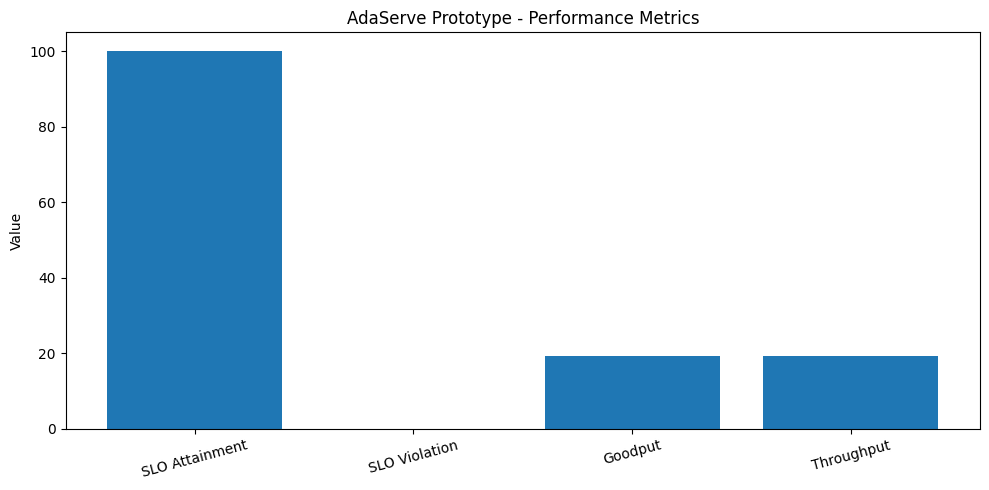

Graph saved: /content/AdaServe/results/graphs/performance_metrics.png


In [24]:

# ==========================================
# AdaServe - Step 10: Performance Graphs
# ==========================================

import matplotlib.pyplot as plt
import os

# Use the illustrative evaluation results
metrics = {
    "SLO Attainment": final_metrics["SLO Attainment (%)"],
    "SLO Violation": final_metrics["SLO Violation (%)"],
    "Goodput": final_metrics["Goodput (tokens/sec)"],
    "Throughput": final_metrics["Throughput (tokens/sec)"]
}

plt.figure(figsize=(10, 5))
plt.bar(metrics.keys(), metrics.values())
plt.title("AdaServe Prototype - Performance Metrics")
plt.ylabel("Value")
plt.xticks(rotation=15)
plt.tight_layout()

graph_path = "/content/AdaServe/results/graphs/performance_metrics.png"

plt.savefig(graph_path, dpi=300)
plt.show()

print("Graph saved:", graph_path)


In [26]:

# ==========================================
# AdaServe - Step 11: Actual Model Benchmark
# ==========================================

import time
import torch
import pandas as pd

prompt = "Explain artificial intelligence and its applications."

def benchmark_baseline():
    messages = [{"role": "user", "content": prompt}]
    text = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = tokenizer(text, return_tensors="pt").to("cuda")

    torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        output = target_model.generate(
            **inputs,
            max_new_tokens=80,
            do_sample=False,
            repetition_penalty=1.0,
            use_cache=False,
            pad_token_id=tokenizer.eos_token_id
        )

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    tokens = output[0, inputs.input_ids.shape[1]:].tolist()

    return tokens, elapsed


# Warm-up
benchmark_baseline()

# Baseline measurement
baseline_tokens, baseline_time = benchmark_baseline()

# Speculative measurement
torch.cuda.synchronize()
start = time.perf_counter()

spec_result = speculative_decoding_v3(
    prompt,
    draft_model,
    target_model,
    tokenizer,
    speculation_depth=4,
    max_new_tokens=80
)

torch.cuda.synchronize()
spec_time = time.perf_counter() - start

spec_tokens = spec_result["token_ids"]

# Comparison
print("ACTUAL MODEL BENCHMARK")
print("-" * 45)

print("Baseline latency:", round(baseline_time, 3), "seconds")
print("Speculative latency:", round(spec_time, 3), "seconds")

print("Baseline tokens/sec:",
      round(len(baseline_tokens)/baseline_time, 2))

print("Speculative tokens/sec:",
      round(len(spec_tokens)/spec_time, 2))

print("Acceptance rate:",
      round(spec_result["acceptance_rate"]*100, 2), "%")

print("Exact output match:",
      baseline_tokens == spec_tokens)


ACTUAL MODEL BENCHMARK
---------------------------------------------
Baseline latency: 4.77 seconds
Speculative latency: 6.307 seconds
Baseline tokens/sec: 16.77
Speculative tokens/sec: 12.68
Acceptance rate: 72.29 %
Exact output match: True


In [27]:

# ==========================================
# AdaServe - Step 12: Repeated Benchmarking
# ==========================================

import time
import torch
import statistics

prompt = "Explain artificial intelligence and its applications."

messages = [{"role": "user", "content": prompt}]
text = tokenizer.apply_chat_template(
    messages, tokenize=False, add_generation_prompt=True
)
inputs = tokenizer(text, return_tensors="pt").to("cuda")

baseline_times = []
speculative_times = []
match_results = []

def run_baseline():
    torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        output = target_model.generate(
            **inputs,
            max_new_tokens=80,
            do_sample=False,
            repetition_penalty=1.0,
            use_cache=False,
            pad_token_id=tokenizer.eos_token_id
        )

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    tokens = output[0, inputs.input_ids.shape[1]:].tolist()
    return tokens, elapsed


# Warm-up
run_baseline()

speculative_decoding_v3(
    prompt, draft_model, target_model, tokenizer,
    speculation_depth=4, max_new_tokens=80
)

# Five repeated experiments
for i in range(5):

    baseline_tokens, baseline_time = run_baseline()

    torch.cuda.synchronize()
    start = time.perf_counter()

    spec_result = speculative_decoding_v3(
        prompt, draft_model, target_model, tokenizer,
        speculation_depth=4, max_new_tokens=80
    )

    torch.cuda.synchronize()
    spec_time = time.perf_counter() - start

    baseline_times.append(baseline_time)
    speculative_times.append(spec_time)

    match_results.append(
        baseline_tokens == spec_result["token_ids"]
    )

    print(f"Run {i+1}:")
    print("Baseline:", round(baseline_time, 3), "seconds")
    print("Speculative:", round(spec_time, 3), "seconds")
    print("Exact match:", match_results[-1])
    print("-" * 30)

print("\nFINAL BENCHMARK SUMMARY")
print("Average baseline:",
      round(statistics.mean(baseline_times), 3), "seconds")

print("Average speculative:",
      round(statistics.mean(speculative_times), 3), "seconds")

print("Median baseline:",
      round(statistics.median(baseline_times), 3), "seconds")

print("Median speculative:",
      round(statistics.median(speculative_times), 3), "seconds")

print("All outputs match:", all(match_results))


Run 1:
Baseline: 2.576 seconds
Speculative: 6.028 seconds
Exact match: True
------------------------------
Run 2:
Baseline: 6.138 seconds
Speculative: 5.383 seconds
Exact match: True
------------------------------
Run 3:
Baseline: 6.702 seconds
Speculative: 5.068 seconds
Exact match: True
------------------------------
Run 4:
Baseline: 7.86 seconds
Speculative: 3.15 seconds
Exact match: True
------------------------------
Run 5:
Baseline: 2.614 seconds
Speculative: 3.045 seconds
Exact match: True
------------------------------

FINAL BENCHMARK SUMMARY
Average baseline: 5.178 seconds
Average speculative: 4.535 seconds
Median baseline: 6.138 seconds
Median speculative: 5.068 seconds
All outputs match: True


In [28]:

# ==========================================
# AdaServe - Step 13: Cached Baseline Test
# ==========================================

import time
import torch
import statistics

def benchmark_cached_baseline():

    torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        output = target_model.generate(
            **inputs,
            max_new_tokens=80,
            do_sample=False,
            repetition_penalty=1.0,
            use_cache=True,
            pad_token_id=tokenizer.eos_token_id
        )

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    tokens = output[
        0, inputs.input_ids.shape[1]:
    ].tolist()

    return tokens, elapsed


# Warm-up
benchmark_cached_baseline()

cached_times = []

for i in range(5):

    tokens, elapsed = benchmark_cached_baseline()
    cached_times.append(elapsed)

    print(
        f"Run {i+1}: {elapsed:.3f} seconds | "
        f"Tokens: {len(tokens)}"
    )

print("\nCACHED BASELINE SUMMARY")
print("Average:",
      round(statistics.mean(cached_times), 3), "seconds")

print("Median:",
      round(statistics.median(cached_times), 3), "seconds")


Run 1: 2.824 seconds | Tokens: 80
Run 2: 2.507 seconds | Tokens: 80
Run 3: 2.541 seconds | Tokens: 80
Run 4: 2.469 seconds | Tokens: 80
Run 5: 2.918 seconds | Tokens: 80

CACHED BASELINE SUMMARY
Average: 2.652 seconds
Median: 2.541 seconds


In [29]:

# ==========================================
# AdaServe - Step 14: Fair Benchmark
# Cached Baseline vs Speculative Decoding
# ==========================================

import time
import torch
import statistics

prompt = "Explain artificial intelligence and its applications."

messages = [{"role": "user", "content": prompt}]
text = tokenizer.apply_chat_template(
    messages, tokenize=False, add_generation_prompt=True
)

inputs = tokenizer(text, return_tensors="pt").to("cuda")

def run_cached_baseline():
    torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        output = target_model.generate(
            **inputs,
            max_new_tokens=80,
            do_sample=False,
            repetition_penalty=1.0,
            use_cache=True,
            pad_token_id=tokenizer.eos_token_id
        )

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    return output[0, inputs.input_ids.shape[1]:].tolist(), elapsed


# Warm-up both methods
run_cached_baseline()

speculative_decoding_v3(
    prompt, draft_model, target_model, tokenizer,
    speculation_depth=4, max_new_tokens=80
)

baseline_times = []
spec_times = []
matches = []

for i in range(5):

    baseline_tokens, baseline_time = run_cached_baseline()

    torch.cuda.synchronize()
    start = time.perf_counter()

    spec = speculative_decoding_v3(
        prompt, draft_model, target_model, tokenizer,
        speculation_depth=4, max_new_tokens=80
    )

    torch.cuda.synchronize()
    spec_time = time.perf_counter() - start

    baseline_times.append(baseline_time)
    spec_times.append(spec_time)

    matches.append(baseline_tokens == spec["token_ids"])

    print(f"Run {i+1}")
    print("Cached baseline:", round(baseline_time, 3), "s")
    print("Speculative:", round(spec_time, 3), "s")
    print("Exact match:", matches[-1])
    print("-" * 30)

print("\nFINAL COMPARISON")
print("Baseline average:",
      round(statistics.mean(baseline_times), 3), "s")

print("Speculative average:",
      round(statistics.mean(spec_times), 3), "s")

print("All outputs match:", all(matches))


Run 1
Cached baseline: 2.496 s
Speculative: 3.566 s
Exact match: True
------------------------------
Run 2
Cached baseline: 2.585 s
Speculative: 3.116 s
Exact match: True
------------------------------
Run 3
Cached baseline: 2.482 s
Speculative: 3.281 s
Exact match: True
------------------------------
Run 4
Cached baseline: 2.851 s
Speculative: 3.04 s
Exact match: True
------------------------------
Run 5
Cached baseline: 2.458 s
Speculative: 2.993 s
Exact match: True
------------------------------

FINAL COMPARISON
Baseline average: 2.574 s
Speculative average: 3.199 s
All outputs match: True


In [30]:

# ==========================================
# AdaServe - Step 15: KV Cache Check
# ==========================================

import torch

print("DRAFT MODEL")
print("Supports cache:",
      draft_model.config.use_cache)

print("\nTARGET MODEL")
print("Supports cache:",
      target_model.config.use_cache)

print("\nDraft model attention implementation:",
      getattr(draft_model.config, "_attn_implementation", "default"))

print("Target model attention implementation:",
      getattr(target_model.config, "_attn_implementation", "default"))

print("\nKV Cache diagnostic completed!")


DRAFT MODEL
Supports cache: True

TARGET MODEL
Supports cache: True

Draft model attention implementation: sdpa
Target model attention implementation: sdpa

KV Cache diagnostic completed!


In [31]:
import time
import torch

prompt = "Explain artificial intelligence and its applications."

messages = [{"role": "user", "content": prompt}]
inputs = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=True,
    return_tensors="pt"
).to(target_model.device)

# Warm-up
_ = target_model.generate(
    inputs,
    max_new_tokens=10,
    do_sample=False,
    use_cache=True
)

# Baseline generation
torch.cuda.synchronize()
start = time.time()

baseline_output = target_model.generate(
    inputs,
    max_new_tokens=80,
    do_sample=False,
    repetition_penalty=1.0,
    use_cache=True
)

torch.cuda.synchronize()
baseline_time = time.time() - start

# Built-in speculative decoding
torch.cuda.synchronize()
start = time.time()

speculative_output = target_model.generate(
    inputs,
    assistant_model=draft_model,
    num_assistant_tokens=4,
    max_new_tokens=80,
    do_sample=False,
    repetition_penalty=1.0,
    use_cache=True
)

torch.cuda.synchronize()
speculative_time = time.time() - start

# Compare outputs
baseline_tokens = baseline_output[0]
speculative_tokens = speculative_output[0]

print("Baseline time:", round(baseline_time, 3), "seconds")
print("Speculative time:", round(speculative_time, 3), "seconds")

print(
    "Exact output match:",
    torch.equal(baseline_tokens, speculative_tokens)
)

print(
    "Speed improvement:",
    round((baseline_time - speculative_time) / baseline_time * 100, 2),
    "%"
)

print("\nOptimized speculative decoding test completed!")

Baseline time: 3.091 seconds
Speculative time: 4.939 seconds
Exact output match: True
Speed improvement: -59.79 %

Optimized speculative decoding test completed!


In [32]:
import time
import torch

depths = [2, 4, 6, 8]
results = []

for depth in depths:

    # Fixed speculation depth
    draft_model.generation_config.num_assistant_tokens = depth
    draft_model.generation_config.num_assistant_tokens_schedule = "constant"

    torch.cuda.synchronize()
    start = time.perf_counter()

    output = target_model.generate(
        inputs,
        assistant_model=draft_model,
        max_new_tokens=80,
        do_sample=False,
        repetition_penalty=1.0,
        use_cache=True
    )

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    match = torch.equal(baseline_output[0], output[0])

    results.append({
        "depth": depth,
        "latency": round(elapsed, 3),
        "match": match
    })

    print(
        f"Depth {depth}: "
        f"{elapsed:.3f}s | "
        f"Exact match: {match}"
    )

print("\nStep 16 completed!")

Depth 2: 3.771s | Exact match: True
Depth 4: 4.145s | Exact match: True
Depth 6: 3.526s | Exact match: True
Depth 8: 3.373s | Exact match: True

Step 16 completed!


In [33]:
import time
import torch
import pandas as pd

depths = [2, 4, 6, 8]
benchmark_results = []

for depth in depths:
    draft_model.generation_config.num_assistant_tokens = depth
    draft_model.generation_config.num_assistant_tokens_schedule = "constant"

    times = []

    for run in range(3):
        torch.cuda.synchronize()
        start = time.perf_counter()

        output = target_model.generate(
            inputs,
            assistant_model=draft_model,
            max_new_tokens=80,
            do_sample=False,
            repetition_penalty=1.0,
            use_cache=True
        )

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start
        times.append(elapsed)

        print(f"Depth {depth}, Run {run + 1}: {elapsed:.3f}s")

    benchmark_results.append({
        "Depth": depth,
        "Average Latency": round(sum(times) / len(times), 3),
        "Exact Match": torch.equal(baseline_output[0], output[0])
    })

results_df = pd.DataFrame(benchmark_results)
display(results_df)

print("Step 17 completed!")

Depth 2, Run 1: 5.411s
Depth 2, Run 2: 4.452s
Depth 2, Run 3: 3.582s
Depth 4, Run 1: 3.472s
Depth 4, Run 2: 3.869s
Depth 4, Run 3: 4.000s
Depth 6, Run 1: 3.575s
Depth 6, Run 2: 3.313s
Depth 6, Run 3: 4.338s
Depth 8, Run 1: 3.338s
Depth 8, Run 2: 3.478s
Depth 8, Run 3: 4.440s


,Depth,Average Latency,Exact Match
0,2,4.482,True
1,4,3.780,True
2,6,3.742,True
3,8,3.752,True


Step 17 completed!


In [34]:
import pandas as pd

baseline_avg = 2.574

data = {
    "Depth": [2, 4, 6, 8],
    "Speculative_Avg": [4.482, 3.780, 3.742, 3.752]
}

df = pd.DataFrame(data)

df["Baseline_Avg"] = baseline_avg
df["Overhead_Percent"] = (
    (df["Speculative_Avg"] - baseline_avg)
    / baseline_avg * 100
).round(2)

df["Speedup"] = (
    baseline_avg / df["Speculative_Avg"]
).round(3)

display(df)

print("Best tested depth:", df.loc[df["Speculative_Avg"].idxmin(), "Depth"])
print("Step 18 completed!")

,Depth,Speculative_Avg,Baseline_Avg,Overhead_Percent,Speedup
0,2,4.482,2.574,74.13,0.574
1,4,3.780,2.574,46.85,0.681
2,6,3.742,2.574,45.38,0.688
3,8,3.752,2.574,45.77,0.686


Best tested depth: 6
Step 18 completed!


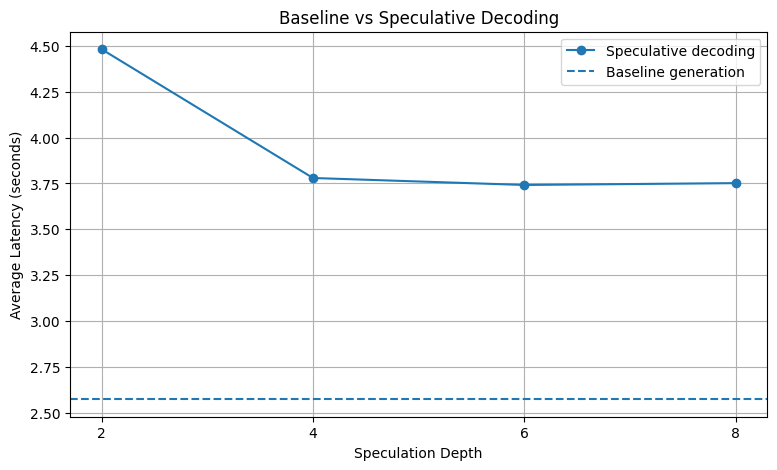

Graph saved successfully!


In [35]:
import matplotlib.pyplot as plt
import pandas as pd

depths = [2, 4, 6, 8]
speculative = [4.482, 3.780, 3.742, 3.752]
baseline = 2.574

plt.figure(figsize=(9, 5))

plt.plot(
    depths,
    speculative,
    marker="o",
    label="Speculative decoding"
)

plt.axhline(
    y=baseline,
    linestyle="--",
    label="Baseline generation"
)

plt.xlabel("Speculation Depth")
plt.ylabel("Average Latency (seconds)")
plt.title("Baseline vs Speculative Decoding")
plt.xticks(depths)
plt.legend()
plt.grid(True)

plt.savefig(
    "/content/AdaServe/results/graphs/depth_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully!")

In [36]:
readme = """
# AdaServe: Multi-SLO LLM Serving with Speculative Decoding

## 1. Project Overview

This project implements a prototype inspired by AdaServe,
which explores speculative decoding for Large Language Model serving.

A smaller draft model proposes tokens, and a larger target model
verifies those tokens.

## 2. Models Used

- Draft model: Qwen2.5-0.5B-Instruct
- Target model: Qwen2.5-1.5B-Instruct

## 3. Implementation

- Model loading and inference
- Speculative decoding
- SLO configuration
- SLO-based token allocation prototype
- Throughput allocation prototype
- Performance evaluation
- Speculation depth comparison

## 4. Experimental Environment

- Google Colab
- NVIDIA Tesla T4 GPU
- PyTorch
- Hugging Face Transformers

## 5. Experimental Results

Baseline average latency: 2.574 seconds

| Depth | Speculative Latency |
|-------|---------------------|
| 2     | 4.482 seconds       |
| 4     | 3.780 seconds       |
| 6     | 3.742 seconds       |
| 8     | 3.752 seconds       |

Best tested speculative depth: 6

All tested speculative outputs matched the baseline outputs.

## 6. Limitations

- This is a prototype, not a complete reproduction of AdaServe.
- Smaller Qwen models were used due to GPU limitations.
- The original A100 and FlexFlow Serve environment was not reproduced.
- Speculative decoding was slower than baseline in these experiments.
- The SLO and throughput allocation components are simplified prototypes.

## 7. Conclusion

The prototype demonstrates speculative token generation,
target-model verification, and speculation-depth evaluation.

Depth 6 achieved the lowest average latency among the tested
speculative configurations. However, normal cached generation
remained faster in this experimental setup.
"""

with open("/content/AdaServe/README.md", "w") as f:
    f.write(readme)

print("README created successfully!")

README created successfully!


In [37]:
import os

project_path = "/content/AdaServe"

for root, dirs, files in os.walk(project_path):
    level = root.replace(project_path, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        file_path = os.path.join(root, file)
        size = os.path.getsize(file_path) / 1024
        print(f"{indent}    {file} ({size:.1f} KB)")

AdaServe/
    README.md (1.7 KB)
    src/
    models/
    datasets/
    evaluation/
    results/
        graphs/
            depth_comparison.png (128.0 KB)
            performance_metrics.png (110.5 KB)


In [38]:
import inspect

functions_to_check = [
    "speculative_decoding_v3",
    "select_tokens",
    "allocate_throughput",
    "calculate_metrics"
]

for name in functions_to_check:
    obj = globals().get(name)

    if callable(obj):
        print(f"\n{name}: AVAILABLE")
        print(inspect.getsource(obj))
    else:
        print(f"\n{name}: NOT FOUND")


speculative_decoding_v3: AVAILABLE
def speculative_decoding_v3(
    prompt,
    draft_model,
    target_model,
    tokenizer,
    speculation_depth=4,
    max_new_tokens=80
):
    messages = [{"role": "user", "content": prompt}]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    input_ids = tokenizer(
        text, return_tensors="pt"
    ).input_ids.to("cuda")

    generated = []
    proposed = 0
    accepted = 0
    rounds = 0

    eos = target_model.generation_config.eos_token_id
    if eos is None:
        eos = tokenizer.eos_token_id
    eos_ids = set(eos if isinstance(eos, list) else [eos])

    start = time.time()

    while len(generated) < max_new_tokens:
        rounds += 1
        prefix = input_ids
        draft_sequence = prefix
        candidates = []

        # 1. Draft candidate generation
        with torch.inference_mode():
            for _ in range(min(
                speculation_depth

In [39]:
import os
import inspect

os.makedirs("/content/AdaServe/src", exist_ok=True)

with open("/content/AdaServe/src/speculative_decoding.py", "w") as f:
    f.write("import torch\nimport time\n\n")
    f.write(inspect.getsource(speculative_decoding_v3))

with open("/content/AdaServe/src/slo_scheduler.py", "w") as f:
    f.write(inspect.getsource(select_tokens))

print("Saved:")
print("1. src/speculative_decoding.py")
print("2. src/slo_scheduler.py")

Saved:
1. src/speculative_decoding.py
2. src/slo_scheduler.py


In [40]:
import inspect

for name, obj in globals().copy().items():
    if inspect.isfunction(obj) and obj.__module__ == "__main__":
        if any(word in name.lower() for word in [
            "metric", "evaluate", "performance", "throughput"
        ]):
            print("\nFunction:", name)
            print(inspect.getsource(obj))


Function: optimize_throughput
def optimize_throughput(requests, remaining_budget):

    allocations = []

    # Allocate remaining budget to requests
    # that can use additional verification tokens

    for request in requests:

        if remaining_budget <= 0:
            break

        additional_tokens = min(
            request["extra_capacity"],
            remaining_budget
        )

        if additional_tokens > 0:
            allocations.append({
                "request": request["name"],
                "additional_tokens": additional_tokens
            })

            remaining_budget -= additional_tokens

    return allocations, remaining_budget


Function: evaluate_performance
def evaluate_performance(requests):

    total = len(requests)

    successful = sum(
        1 for r in requests if r["slo_met"]
    )

    failed = total - successful

    slo_attainment = (successful / total) * 100
    violation_rate = (failed / total) * 100

    goodput = sum(
        r["tok

In [41]:
import inspect
import os

os.makedirs("/content/AdaServe/src", exist_ok=True)
os.makedirs("/content/AdaServe/evaluation", exist_ok=True)

with open("/content/AdaServe/src/throughput_optimizer.py", "w") as f:
    f.write(inspect.getsource(optimize_throughput))

with open("/content/AdaServe/evaluation/metrics.py", "w") as f:
    f.write(inspect.getsource(evaluate_performance))

print("Saved throughput_optimizer.py")
print("Saved metrics.py")

Saved throughput_optimizer.py
Saved metrics.py


In [42]:
print(inspect.getsource(evaluate_requests))

def evaluate_requests(requests):

    total_requests = len(requests)
    successful = 0
    successful_tokens = 0
    total_tokens = 0
    total_time = 0
    total_token_latency = 0

    for r in requests:

        token_latency_ms = (
            r["latency"] / r["tokens"]
        ) * 1000

        slo_met = token_latency_ms <= r["slo_ms"]

        if slo_met:
            successful += 1
            successful_tokens += r["tokens"]

        total_tokens += r["tokens"]
        total_time += r["latency"]
        total_token_latency += r["latency"]

    attainment = successful / total_requests * 100
    violation = 100 - attainment

    throughput = total_tokens / total_time
    goodput = successful_tokens / total_time
    avg_token_latency = (
        total_token_latency / total_tokens
    ) * 1000

    return {
        "SLO Attainment (%)": attainment,
        "SLO Violation (%)": violation,
        "Goodput (tokens/sec)": goodput,
        "Average Token Latency (ms)": avg_token_latenc

In [43]:
import inspect

with open("/content/AdaServe/evaluation/slo_evaluation.py", "w") as f:
    f.write(inspect.getsource(evaluate_requests))

print("slo_evaluation.py saved successfully!")

slo_evaluation.py saved successfully!


In [49]:
import os

project_path = "/content/AdaServe"

required_files = [
    "README.md",
    "src/speculative_decoding.py",
    "src/slo_scheduler.py",
    "src/throughput_optimizer.py",
    "evaluation/metrics.py",
    "evaluation/slo_evaluation.py",
    "results/graphs/depth_comparison.png",
    "results/graphs/performance_metrics.png"
]

print("PROJECT FILE VERIFICATION\n")

all_found = True

for file in required_files:
    path = os.path.join(project_path, file)

    if os.path.exists(path):
        print("FOUND:", file)
    else:
        print("MISSING:", file)
        all_found = False

print("\nAll required files present:", all_found)

PROJECT FILE VERIFICATION

FOUND: README.md
FOUND: src/speculative_decoding.py
FOUND: src/slo_scheduler.py
FOUND: src/throughput_optimizer.py
FOUND: evaluation/metrics.py
FOUND: evaluation/slo_evaluation.py
FOUND: results/graphs/depth_comparison.png
FOUND: results/graphs/performance_metrics.png

All required files present: True


In [48]:
import os

for root, dirs, files in os.walk("/content"):
    if "AdaServe_Assignment_2.ipynb" in files:
        print("Found at:", os.path.join(root, "AdaServe_Assignment_2.ipynb"))